# 04 — Apprentissage non supervisé : clustering et détection d'anomalies

**Rôle :** découvrir des groupes de flux **sans utiliser les étiquettes** (parcours B du cours), puis vérifier
a posteriori si ces groupes correspondent aux catégories d'attaque ; et détecter des intrusions comme des
**anomalies** par rapport au trafic normal (utile pour des attaques inconnues).

Algorithmes : **K-Means** (coude, k-means++), **K-Medoids PAM** et **CLARA** (implémentés), **AGNES**
(Ward, complète, moyenne, simple), **DIANA** (implémenté), **DBSCAN**, **GMM** ; détecteurs Isolation Forest,
LOF, distance au centroïde, log-vraisemblance GMM. Code : `src/unsupervised/clustering.py`, `src/run_unsupervised.py`.

In [1]:
# Configuration : le notebook s'exécute depuis notebooks/, on ajoute la racine du dépôt au chemin
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src import config as C
from src import visualization as V
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
print('Racine du projet :', ROOT.name)

Racine du projet : Network-Intrusion-Detection-System


In [2]:
RUN = False
from src import run_unsupervised as RU
if RUN or not (C.METRICS_DIR / 'unsupervised.json').exists():
    RU.main()
u = json.loads((C.METRICS_DIR / 'unsupervised.json').read_text(encoding='utf-8'))
print(f"Espace : 10 composantes principales ({sum(u['pca_explained']):.1%} de variance) ; k coude = {u['k_elbow']}, k silhouette = {u['k_silhouette']}")

PCA : 90.0% de variance sur 10 composantes


K-Means : coude k=6, silhouette max k=10


Robustesse : {'pam_center_shift': 18.550742795591237, 'kmeans_center_shift': 68.89273540486492, 'outliers_injected': 30}


                                    algorithm  n_clusters  silhouette  davies_bouldin  adjusted_rand_cat  purity_cat  purity_binary
0                      K-Means++ (k=6, coude)           6       0.453           0.848              0.343       0.703          0.913
1            K-Means++ (k=10 = nb catégories)          10       0.511           0.686              0.272       0.698          0.896
2                 K-Medoids PAM (k=6, n=1500)           6       0.463           0.816              0.351       0.703          0.912
3   K-Means++ (k=6, n=1500, même échantillon)           6       0.462           0.813              0.347       0.703          0.911
4                          CLARA (k=6, 5×800)           6       0.457           0.846              0.347       0.703          0.914
5                    AGNES ward (k=6, n=2000)           6       0.404           0.843              0.296       0.656          0.867
6                AGNES complete (k=6, n=2000)           6       0.308       

                        detector                                   mode  roc_auc  pr_auc  best_f1  precision_at_best  recall_at_best  threshold
0               Isolation Forest  non supervisé (train sans étiquettes)   0.6804  0.4882   0.6379             0.4818          0.9434     0.4004
1               Isolation Forest      semi-supervisé (normal seulement)   0.8995  0.7221   0.8364             0.7334          0.9731     0.4644
2           Local Outlier Factor      semi-supervisé (normal seulement)   0.7597  0.7229   0.6432             0.6302          0.6567     1.1517
3  Distance au centroïde K-Means      semi-supervisé (normal seulement)   0.9571  0.8716   0.8977             0.8229          0.9875     2.5707
4          Log-vraisemblance GMM      semi-supervisé (normal seulement)   0.9844  0.9668   0.9371             0.9237          0.9509    14.7698


Apriori : 20527 itemsets fréquents, 48173 règles (conf≥0.7), 3155 règles vers la classe, 952 vers une catégorie
Terminé en 505s
Espace : 10 composantes principales (90.0% de variance) ; k coude = 6, k silhouette = 10


## 1. K-Means : choix de k
- **Méthode du coude** : l'inertie intra-classe (WCSS) diminue toujours avec k ; on cherche le point où le gain
  marginal s'effondre (détecté automatiquement par la distance maximale à la corde).
- **Silhouette** s(i) = (b − a)/max(a, b) ∈ [−1, 1] et **Davies-Bouldin** (↓) complètent le diagnostic.
- **k-means++** (initialisation dispersée) vs aléatoire.

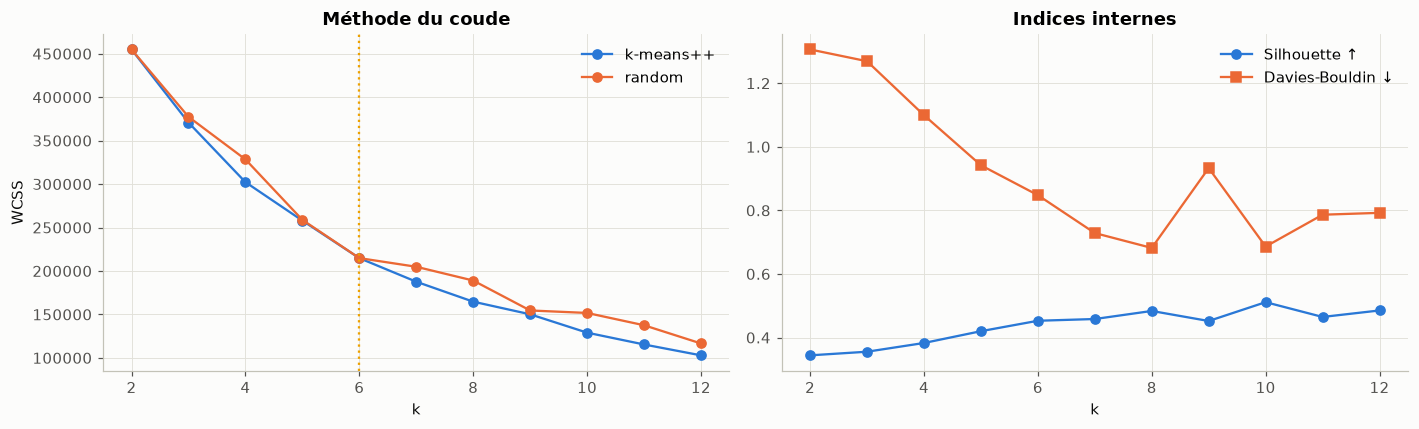

In [3]:
km = pd.DataFrame(u['kmeans_scan'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (init, g) in enumerate(km.groupby('init')):
    axes[0].plot(g.k, g.inertia_wcss, marker='o', label=init, color=V.SERIES[i])
axes[0].axvline(u['k_elbow'], ls=':', color='#eda100'); axes[0].set_xlabel('k'); axes[0].set_ylabel('WCSS'); axes[0].legend(); axes[0].set_title('Méthode du coude')
g = km[km.init == 'k-means++']
axes[1].plot(g.k, g.silhouette, marker='o', label='Silhouette ↑', color=V.SERIES[0]); axes[1].plot(g.k, g.davies_bouldin, marker='s', label='Davies-Bouldin ↓', color=V.SERIES[1])
axes[1].set_xlabel('k'); axes[1].legend(); axes[1].set_title('Indices internes')
plt.tight_layout(); V.save(fig, '04_kmeans_elbow_silhouette'); plt.show()

## 2. Comparaison de tous les algorithmes
Indices **internes** (silhouette, DB, Calinski-Harabasz) et **externes** vs les 10 catégories réelles (Rand Index, ARI, NMI, pureté).

In [4]:
cmp = pd.DataFrame(u['comparison'])
display(cmp[['algorithm', 'n_clusters', 'noise_pct', 'silhouette', 'davies_bouldin', 'calinski_harabasz', 'rand_index_cat', 'adjusted_rand_cat', 'nmi_cat', 'purity_cat', 'purity_binary']].round(3))

,algorithm,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,rand_index_cat,adjusted_rand_cat,nmi_cat,purity_cat,purity_binary
0,"K-Means++ (k=6, coude)",6,0.0,0.453,0.848,8362.221,0.701,0.343,0.393,0.703,0.913
1,K-Means++ (k=10 = nb catégories),10,0.0,0.511,0.686,9207.373,0.673,0.272,0.353,0.698,0.896
2,"K-Medoids PAM (k=6, n=1500)",6,0.0,0.463,0.816,758.952,0.705,0.351,0.406,0.703,0.912
3,"K-Means++ (k=6, n=1500, même échantillon)",6,0.0,0.462,0.813,760.427,0.704,0.347,0.403,0.703,0.911
4,"CLARA (k=6, 5×800)",6,0.0,0.457,0.846,8332.464,0.702,0.347,0.396,0.703,0.914
5,"AGNES ward (k=6, n=2000)",6,0.0,0.404,0.843,760.714,0.684,0.296,0.344,0.656,0.867
6,"AGNES complete (k=6, n=2000)",6,0.0,0.308,1.081,418.747,0.614,0.174,0.187,0.631,0.720
7,"AGNES average (k=6, n=2000)",6,0.0,0.249,0.754,84.430,0.425,0.017,0.043,0.619,0.630
8,"AGNES single (k=6, n=2000)",6,0.0,0.232,0.580,45.825,0.393,-0.021,0.014,0.614,0.614
9,"DIANA (k=6, n=700)",6,0.0,0.326,0.897,150.286,0.545,0.071,0.119,0.634,0.644


## 3. Projection ACP et correspondance clusters / catégories

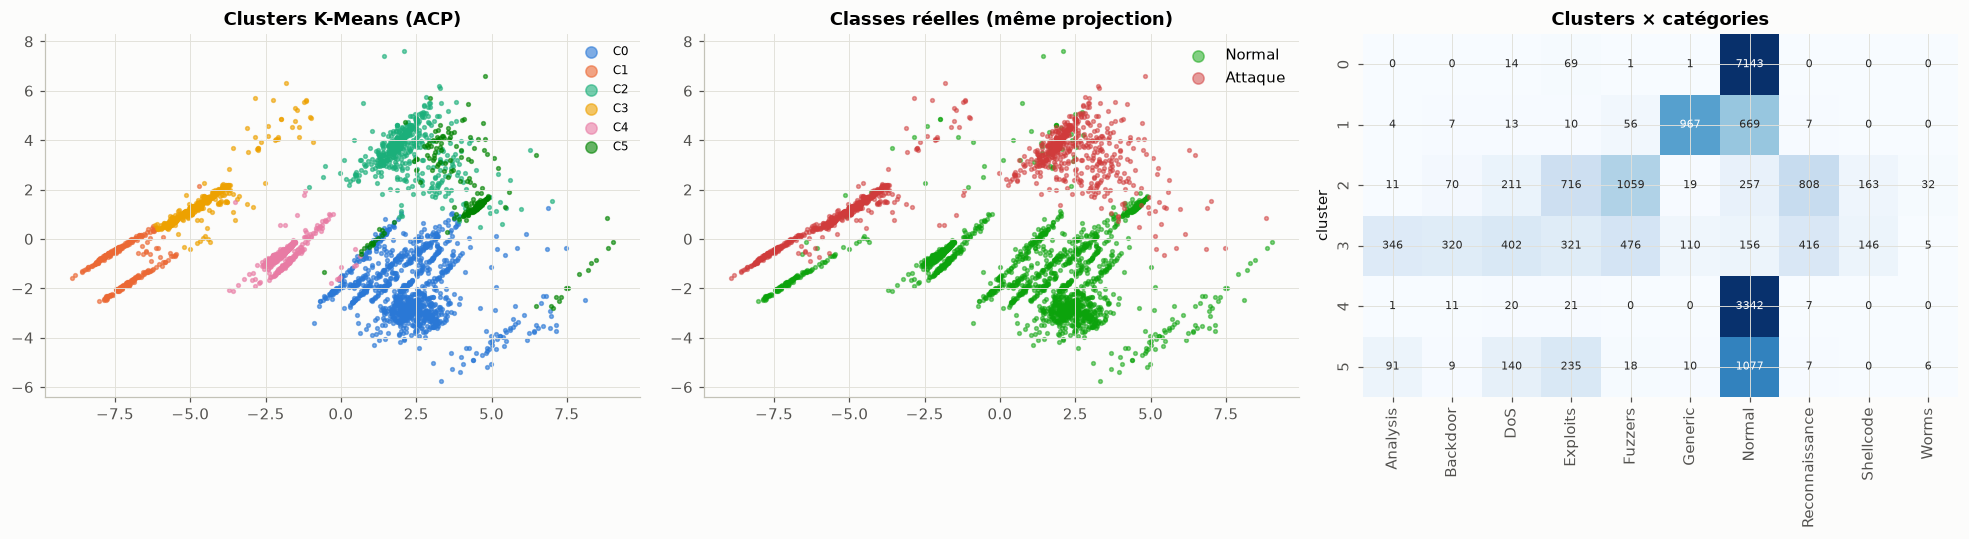

,cluster,taille,pct_attaque,sbytes_med,dbytes_med,dur_med,sttl_med,proto_mode,service_mode,state_mode,categorie_dominante
0,0,7228,0.012,3234.0,14992.0,0.046,31.0,tcp,-,fin,Normal
1,1,1733,0.614,114.0,0.0,0.000,254.0,udp,dns,int,Generic
2,2,3346,0.923,848.0,354.0,0.830,254.0,tcp,-,fin,Fuzzers
3,3,2698,0.942,200.0,0.0,0.000,254.0,udp,-,int,Fuzzers
4,4,3402,0.018,146.0,178.0,0.001,31.0,udp,dns,con,Normal
5,5,1593,0.324,1580.0,10168.0,1.012,31.0,tcp,http,fin,Normal


In [5]:
P = u['pca_points']; pts = pd.DataFrame(P)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for k, g in pts.groupby('cluster'):
    axes[0].scatter(g.x, g.y, s=6, alpha=0.6, color=V.SERIES[k % 8], label=f'C{k}')
axes[0].legend(markerscale=3, fontsize=8); axes[0].set_title('Clusters K-Means (ACP)')
for lab, g in pts.groupby('label'):
    axes[1].scatter(g.x, g.y, s=6, alpha=0.5, color=V.NORMAL if lab == 0 else V.ATTACK, label='Normal' if lab == 0 else 'Attaque')
axes[1].legend(markerscale=3); axes[1].set_title('Classes réelles (même projection)')
ct = pd.DataFrame(u['cluster_vs_category']['values'], index=u['cluster_vs_category']['index'], columns=u['cluster_vs_category']['columns'])
sns.heatmap(ct.div(ct.sum(1), axis=0), annot=ct, fmt='d', cmap=V.SEQ_CMAP, ax=axes[2], cbar=False, annot_kws={'size': 7})
axes[2].set_title('Clusters × catégories'); axes[2].set_ylabel('cluster')
plt.tight_layout(); V.save(fig, '04_pca_clusters'); plt.show()
display(pd.DataFrame(u['profiles']).round(3))

## 4. Clustering hiérarchique : AGNES (ascendant) et DIANA (descendant)
La **corrélation cophénétique** mesure la fidélité du dendrogramme aux distances d'origine.

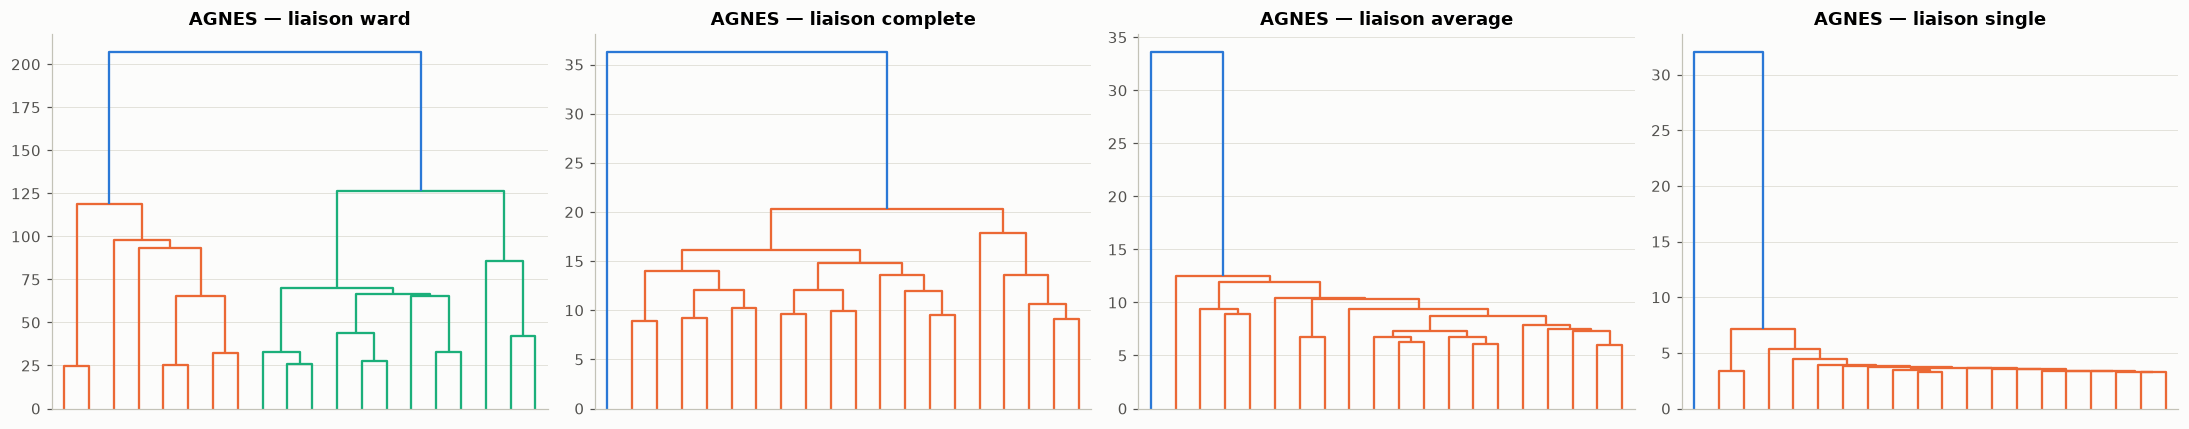

,linkage,k,cophenetic_corr,largest_cluster_pct,silhouette,davies_bouldin,calinski_harabasz
0,ward,6,0.591,37.95,0.404,0.843,760.714
1,complete,6,0.706,39.80,0.308,1.081,418.747
2,average,6,0.847,95.50,0.249,0.754,84.430
3,single,6,0.702,98.00,0.232,0.580,45.825


DIANA — scissions : [{'split_cluster_size': 700, 'diameter': 36.27904582628224, 'sizes': [3, 697]}, {'split_cluster_size': 697, 'diameter': 20.007052116703495, 'sizes': [19, 678]}, {'split_cluster_size': 678, 'diameter': 20.007052116703495, 'sizes': [393, 285]}, {'split_cluster_size': 393, 'diameter': 15.773342317513897, 'sizes': [25, 368]}, {'split_cluster_size': 19, 'diameter': 14.080545078506761, 'sizes': [3, 16]}]


In [6]:
import joblib
from scipy.cluster.hierarchy import dendrogram
lk = joblib.load(C.ALL_MODELS_DIR / 'linkages.joblib')
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, m in zip(axes, ['ward', 'complete', 'average', 'single']):
    dendrogram(lk[m], truncate_mode='lastp', p=20, ax=ax, color_threshold=None, above_threshold_color=V.SERIES[0], no_labels=True)
    ax.set_title(f'AGNES — liaison {m}')
plt.tight_layout(); V.save(fig, '04_dendrograms'); plt.show()
display(pd.DataFrame(u['agnes']).round(3))
print('DIANA — scissions :', u['diana_history'])

**Lecture :** la liaison *simple* produit l'effet de chaîne (un énorme cluster + singletons) ; *Ward* donne des
groupes équilibrés. DIANA, descendant, isole d'abord le groupe le plus éloigné (les flux d'attaque atypiques).

## 5. DBSCAN et GMM

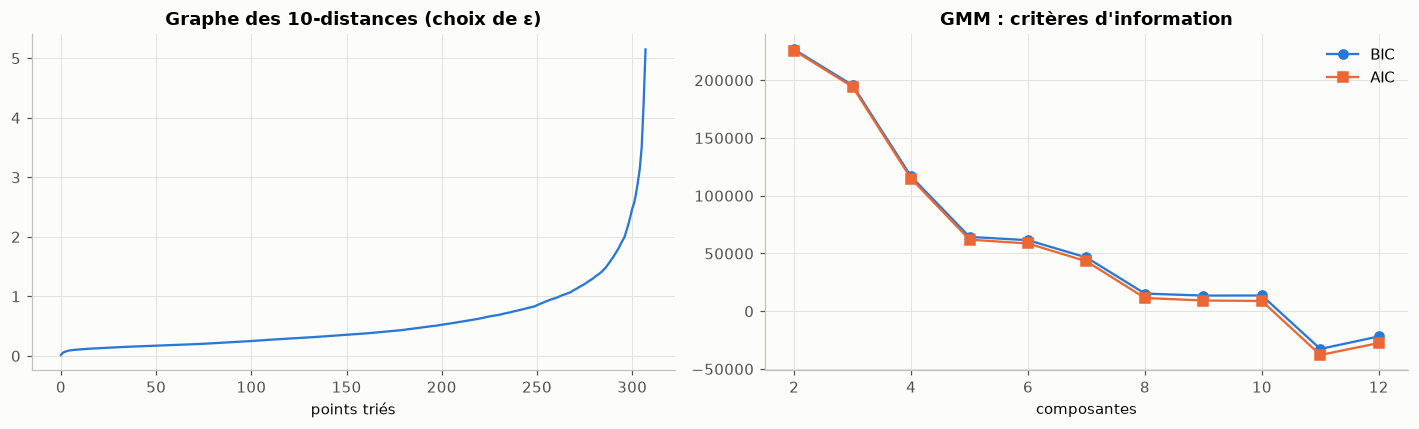

,eps,min_samples,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz
0,0.455,5,73,24.900,0.299,0.723,774.731
1,0.455,10,36,32.788,0.513,0.618,4161.781
2,0.455,20,23,41.963,0.535,0.512,6272.691
3,0.695,5,56,12.812,0.319,0.720,1037.944
4,0.695,10,34,18.150,0.406,0.763,1565.512
5,0.695,20,28,25.412,0.470,0.608,4891.801
6,1.248,5,31,4.000,0.270,0.734,1159.522
7,1.248,10,28,6.188,0.315,0.788,1565.506
8,1.248,20,16,10.575,0.397,0.769,2604.040
9,1.778,5,25,1.713,0.361,0.689,1163.441


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(u['k_distance'], color=V.SERIES[0]); axes[0].set_title('Graphe des 10-distances (choix de ε)'); axes[0].set_xlabel('points triés')
gm = pd.DataFrame(u['gmm_scan'])
axes[1].plot(gm.k, gm.bic, marker='o', label='BIC'); axes[1].plot(gm.k, gm.aic, marker='s', label='AIC'); axes[1].legend(); axes[1].set_title('GMM : critères d\'information'); axes[1].set_xlabel('composantes')
plt.tight_layout(); V.save(fig, '04_dbscan_gmm'); plt.show()
display(pd.DataFrame(u['dbscan_scan']).round(3))

## 6. Robustesse : K-Medoids (PAM) vs K-Means

In [8]:
print(u['robustness'])
print('Un medoïde est un point réel du jeu : les valeurs aberrantes injectées le déplacent moins qu\'une moyenne.')

{'pam_center_shift': 18.550742795591237, 'kmeans_center_shift': 68.89273540486492, 'outliers_injected': 30}
Un medoïde est un point réel du jeu : les valeurs aberrantes injectées le déplacent moins qu'une moyenne.


## 7. Détection d'intrusions par anomalies

,detector,mode,roc_auc,pr_auc,best_f1,precision_at_best,recall_at_best,threshold
0,Isolation Forest,non supervisé (train sans étiquettes),0.6804,0.4882,0.6379,0.4818,0.9434,0.4004
1,Isolation Forest,semi-supervisé (normal seulement),0.8995,0.7221,0.8364,0.7334,0.9731,0.4644
2,Local Outlier Factor,semi-supervisé (normal seulement),0.7597,0.7229,0.6432,0.6302,0.6567,1.1517
3,Distance au centroïde K-Means,semi-supervisé (normal seulement),0.9571,0.8716,0.8977,0.8229,0.9875,2.5707
4,Log-vraisemblance GMM,semi-supervisé (normal seulement),0.9844,0.9668,0.9371,0.9237,0.9509,14.7698


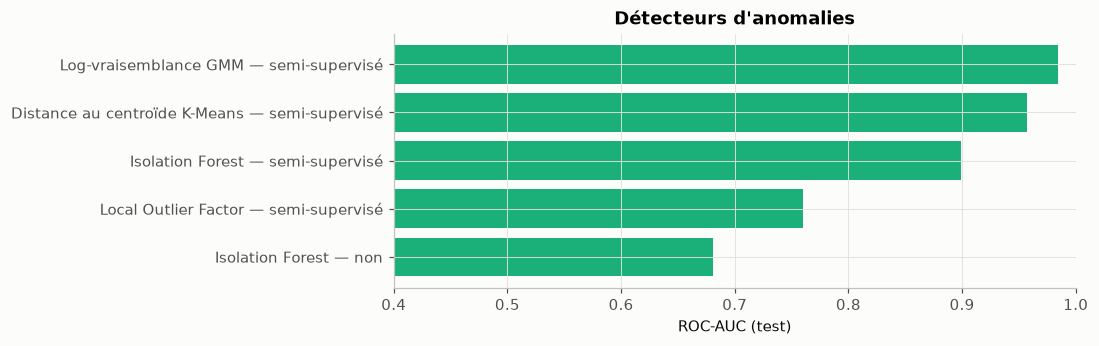

In [9]:
an = pd.DataFrame(u['anomaly'])
display(an.round(4))
fig, ax = plt.subplots(figsize=(8, 3))
s = an.sort_values('roc_auc'); ax.barh(s.detector + ' — ' + s['mode'].str.split().str[0], s.roc_auc, color=V.SERIES[2])
ax.set_xlim(0.4, 1); ax.set_xlabel('ROC-AUC (test)'); ax.set_title('Détecteurs d\'anomalies'); V.save(fig, '04_anomaly_detection'); plt.show()

## 8. Conclusion
- Les clusters retrouvent la **séparation normal / attaque** (pureté binaire élevée) mais pas finement les
  10 catégories (ARI modéré) : sans étiquettes, DoS/Exploits/Analysis/Backdoor restent indiscernables.
- Le meilleur compromis interne/externe est obtenu par K-Means / Ward ; DBSCAN isole du bruit utile (flux rares).
- Les détecteurs appris sur le seul trafic normal atteignent une ROC-AUC élevée **sans jamais voir d'attaque** :
  complément intéressant d'un classifieur supervisé pour les attaques inédites.